# Explainable Machine Learning for Cardiovascular Risk Prediction Using Random Forest
### Dataset: Cardiovascular Disease Dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from xgboost import XGBClassifier
import shap

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files
import os

if os.path.exists('/content/cardio_train.csv'):
    file_path = '/content/cardio_train.csv'
    print("Dataset already found.")
else:
    print("Please upload cardio_train.csv")
    uploaded = files.upload()
    file_path = next(iter(uploaded))

df = pd.read_csv(file_path, sep=';')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset already found.
Dataset loaded successfully!
Shape: (70000, 13)


In [3]:
##  Dataset Loading and Initial Inspection
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Rows: 70000
Columns: 13

Column names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [5]:
###  Missing Values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

Total missing values: 0


In [6]:
###  Duplicate Records
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


cardio
0    35021
1    34979
Name: count, dtype: int64


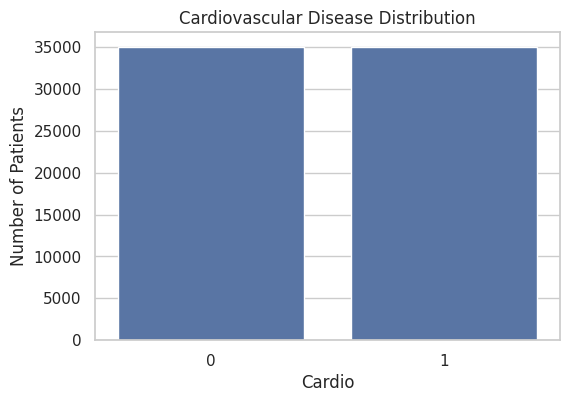

In [7]:
###  Target Variable Distribution

print(df['cardio'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x='cardio', data=df)
plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Cardio")
plt.ylabel("Number of Patients")
plt.show()

In [8]:
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


Age in years:
count    70000.000000
mean        53.302850
std          6.754967
min         29.563313
25%         48.361396
50%         53.943874
75%         58.390144
max         64.922656
Name: age_years, dtype: float64


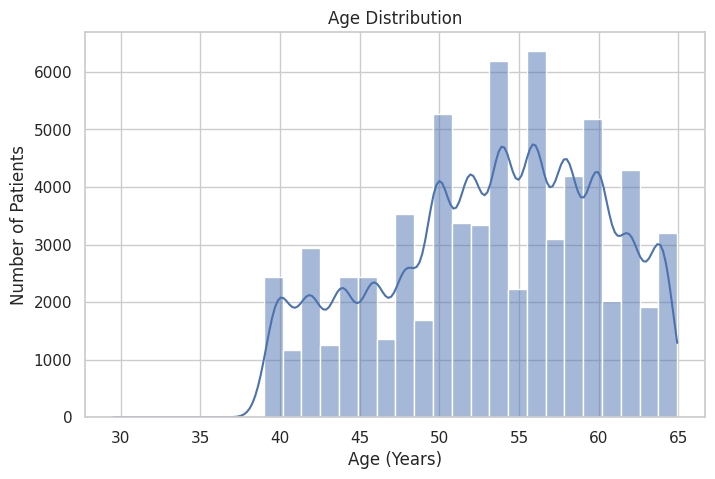

In [9]:
df['age_years'] = df['age'] / 365.25

print("Age in years:")
print(df['age_years'].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df['age_years'], bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Patients")
plt.show()

In [10]:
df['height_m'] = df['height'] / 100

df['bmi'] = df['weight'] / (df['height_m'] ** 2)

print(df[['height', 'weight', 'bmi']].head())

   height  weight        bmi
0     168    62.0  21.967120
1     156    85.0  34.927679
2     165    64.0  23.507805
3     169    82.0  28.710479
4     156    56.0  23.011177


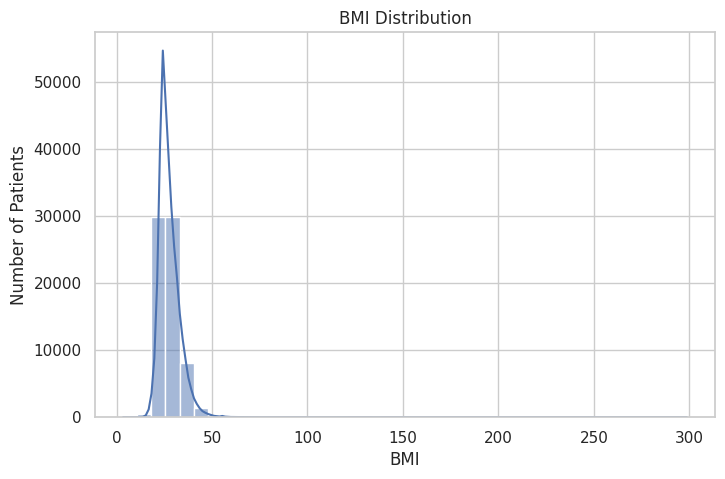

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df['bmi'], bins=40, kde=True)
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of Patients")
plt.show()

In [12]:
categorical_columns = [
    'gender',
    'cholesterol',
    'gluc',
    'smoke',
    'alco',
    'active'
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 gender
gender
1    45530
2    24470
Name: count, dtype: int64

 cholesterol
cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64

 gluc
gluc
1    59479
3     5331
2     5190
Name: count, dtype: int64

 smoke
smoke
0    63831
1     6169
Name: count, dtype: int64

 alco
alco
0    66236
1     3764
Name: count, dtype: int64

 active
active
1    56261
0    13739
Name: count, dtype: int64


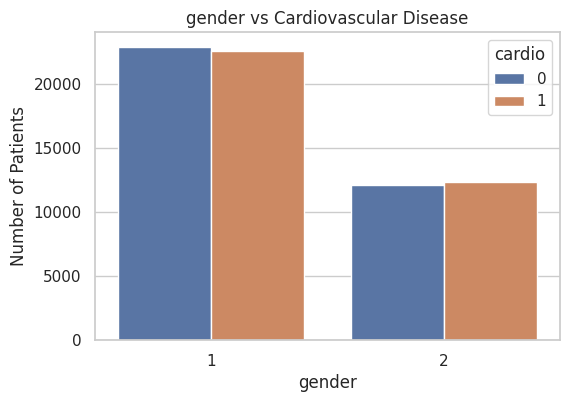

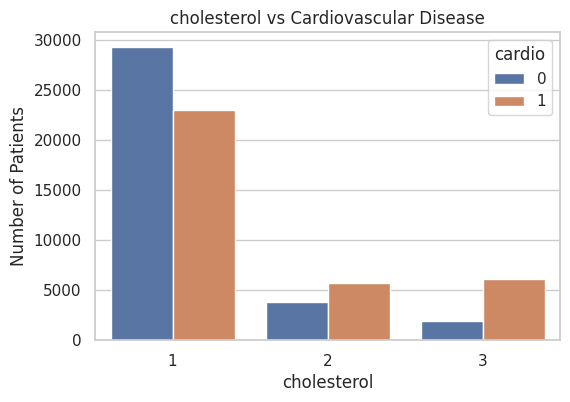

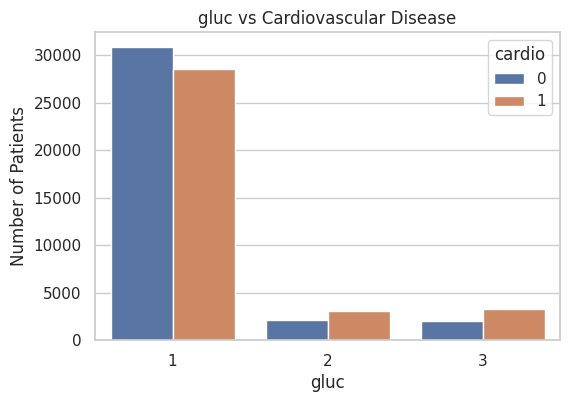

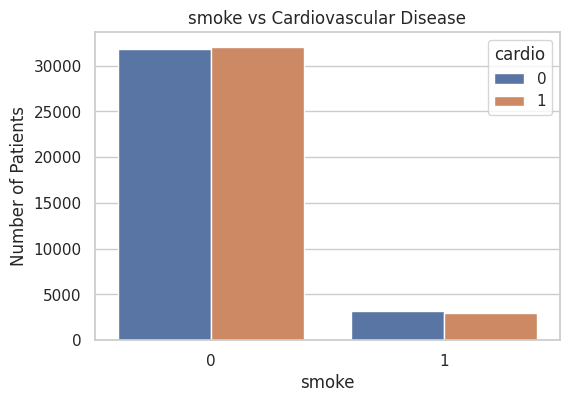

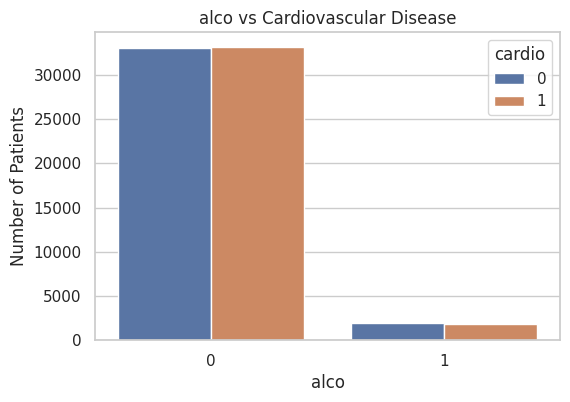

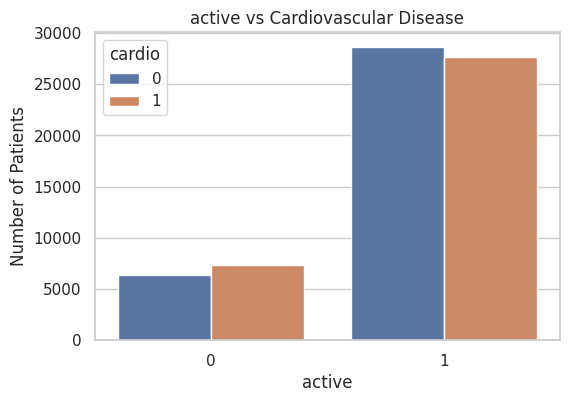

In [13]:
for column in categorical_columns:

    plt.figure(figsize=(6, 4))

    sns.countplot(
        x=column,
        hue='cardio',
        data=df
    )

    plt.title(f"{column} vs Cardiovascular Disease")
    plt.xlabel(column)
    plt.ylabel("Number of Patients")
    plt.show()

In [14]:
print("Systolic BP:")
print(df['ap_hi'].describe())

print("\nDiastolic BP:")
print(df['ap_lo'].describe())

print("\nSystolic BP <= 0:", (df['ap_hi'] <= 0).sum())
print("Diastolic BP <= 0:", (df['ap_lo'] <= 0).sum())

Systolic BP:
count    70000.000000
mean       128.817286
std        154.011419
min       -150.000000
25%        120.000000
50%        120.000000
75%        140.000000
max      16020.000000
Name: ap_hi, dtype: float64

Diastolic BP:
count    70000.000000
mean        96.630414
std        188.472530
min        -70.000000
25%         80.000000
50%         80.000000
75%         90.000000
max      11000.000000
Name: ap_lo, dtype: float64

Systolic BP <= 0: 7
Diastolic BP <= 0: 22


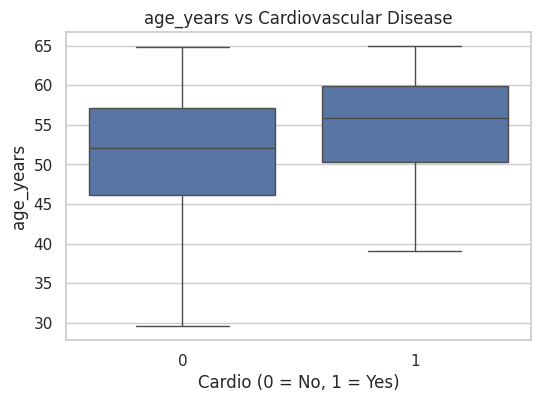

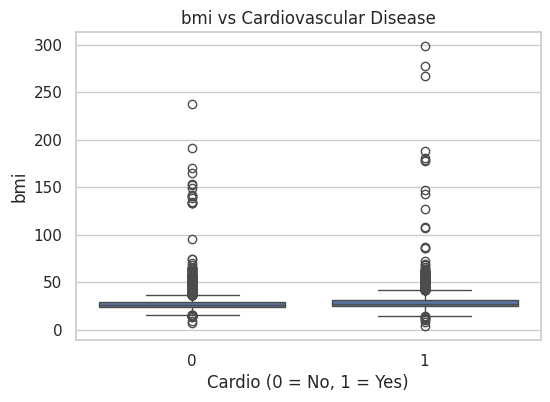

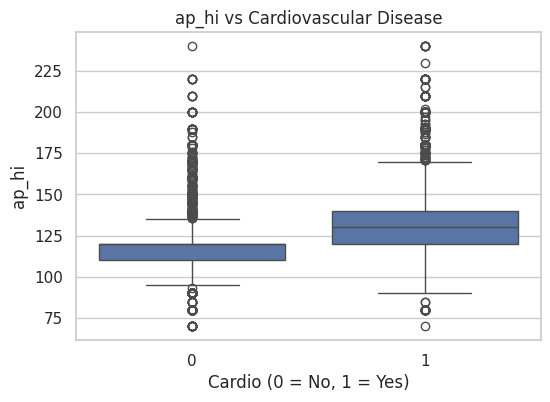

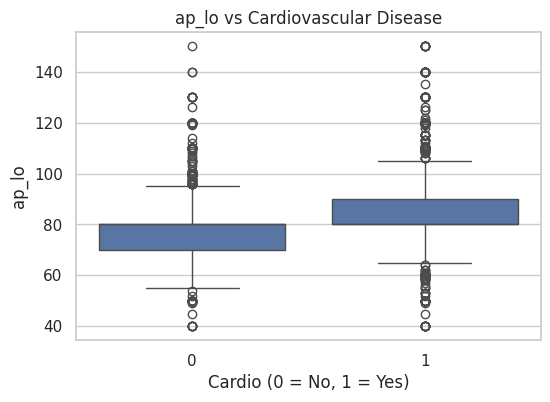

In [15]:
# Boxplots of key numeric features vs cardiovascular disease
# (extreme BP values filtered only for plotting, so the boxes are readable)
plot_df = df[df['ap_hi'].between(70, 250) & df['ap_lo'].between(40, 150)]

for col in ['age_years', 'bmi', 'ap_hi', 'ap_lo']:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='cardio', y=col, data=plot_df)
    plt.title(f"{col} vs Cardiovascular Disease")
    plt.xlabel("Cardio (0 = No, 1 = Yes)")
    plt.show()

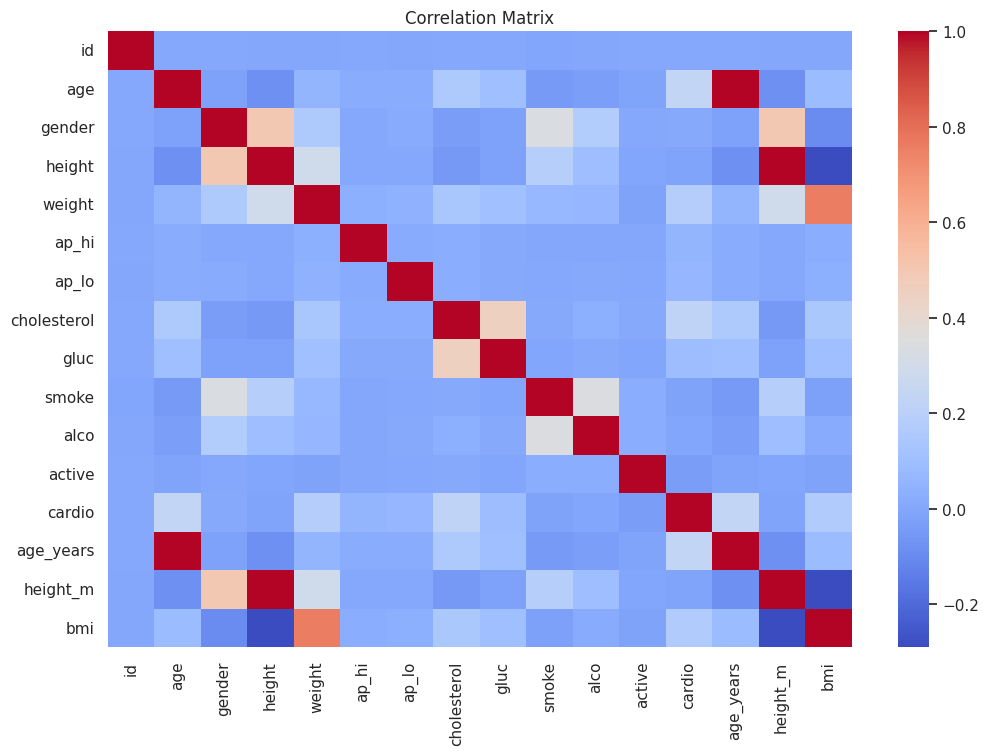

In [16]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=False,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

In [17]:
numerical_columns = [
    'age_years',
    'height',
    'weight',
    'ap_hi',
    'ap_lo',
    'bmi'
]

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[column] < lower) | (df[column] > upper)).sum()

    print(column, ":", outliers, "potential outliers")

age_years : 4 potential outliers
height : 519 potential outliers
weight : 1819 potential outliers
ap_hi : 1435 potential outliers
ap_lo : 4632 potential outliers
bmi : 1995 potential outliers


In [18]:
##  Data Preprocessing
data = df[(df.ap_hi.between(70, 250)) & (df.ap_lo.between(40, 150)) &
          (df.ap_hi > df.ap_lo) &
          (df.height.between(120, 220)) & (df.weight.between(30, 200))].copy()

data['age_years'] = data['age'] / 365.25
data['bmi'] = data['weight'] / (data['height'] / 100) ** 2

data = data.drop(columns=['id', 'age', 'height_m'])

print("Original records:", len(df))
print("Records after preprocessing:", len(data))
print("Records removed:", len(df) - len(data))
print("Final shape:", data.shape)

Original records: 70000
Records after preprocessing: 68610
Records removed: 1390
Final shape: (68610, 13)


In [19]:
X = data.drop(columns=['cardio'])
y = data['cardio']

print("Features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi']

X shape: (68610, 12)
y shape: (68610,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (54888, 12)
Testing data: (13722, 12)


In [21]:
##  Machine Learning Models

###  Logistic Regression
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions))

Logistic Regression Accuracy: 72.89 %

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.78      0.74      6934
           1       0.75      0.67      0.71      6788

    accuracy                           0.73     13722
   macro avg       0.73      0.73      0.73     13722
weighted avg       0.73      0.73      0.73     13722



In [22]:
###  Decision Tree
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

decision_tree_predictions = decision_tree_model.predict(X_test)

decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_predictions
)

print("Decision Tree Accuracy:",
      round(decision_tree_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, decision_tree_predictions))

Decision Tree Accuracy: 63.82 %

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.64      0.64      6934
           1       0.63      0.63      0.63      6788

    accuracy                           0.64     13722
   macro avg       0.64      0.64      0.64     13722
weighted avg       0.64      0.64      0.64     13722



In [23]:
###  Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1

)

random_forest_model.fit(X_train, y_train)

random_forest_predictions = random_forest_model.predict(X_test)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_predictions
)

print("Random Forest Accuracy:",
      round(random_forest_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, random_forest_predictions))

Random Forest Accuracy: 73.68 %

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.78      0.75      6934
           1       0.76      0.69      0.72      6788

    accuracy                           0.74     13722
   macro avg       0.74      0.74      0.74     13722
weighted avg       0.74      0.74      0.74     13722



In [24]:
###  XGBoost
xgboost_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric='logloss'
)

xgboost_model.fit(X_train, y_train)

xgboost_predictions = xgboost_model.predict(X_test)

xgboost_accuracy = accuracy_score(
    y_test,
    xgboost_predictions
)

print("XGBoost Accuracy:",
      round(xgboost_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, xgboost_predictions))

XGBoost Accuracy: 73.01 %

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.77      0.74      6934
           1       0.74      0.69      0.72      6788

    accuracy                           0.73     13722
   macro avg       0.73      0.73      0.73     13722
weighted avg       0.73      0.73      0.73     13722



In [25]:
### Model Comparison
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy (%)': [
        logistic_accuracy * 100,
        decision_tree_accuracy * 100,
        random_forest_accuracy * 100,
        xgboost_accuracy * 100
    ]
})

model_results['Accuracy (%)'] = model_results['Accuracy (%)'].round(2)

print(model_results)

                 Model  Accuracy (%)
0  Logistic Regression         72.89
1        Decision Tree         63.82
2        Random Forest         73.68
3              XGBoost         73.01


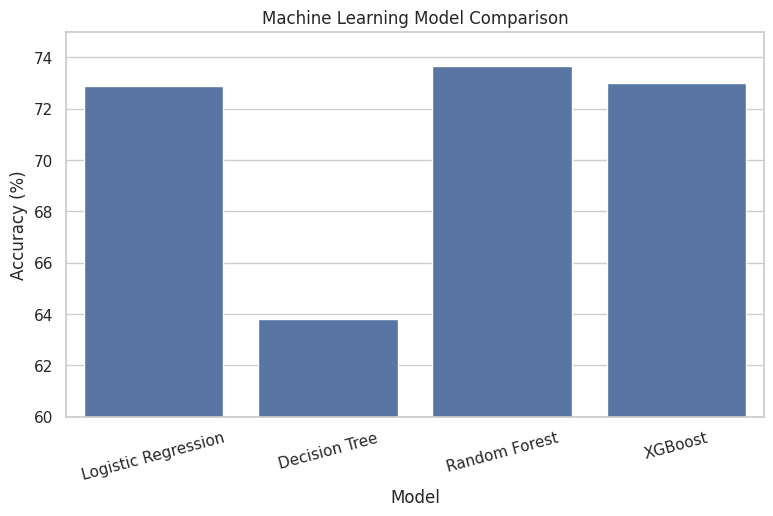

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x='Model',
    y='Accuracy (%)',
    data=model_results
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(60, 75)

plt.xticks(rotation=15)
plt.show()

In [27]:
##  Random Forest Feature Importance
feature_importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

ap_hi          0.369389
ap_lo          0.176065
age_years      0.153322
bmi            0.079751
cholesterol    0.078156
weight         0.056948
height         0.042264
gluc           0.015003
active         0.010215
gender         0.007160
smoke          0.006251
alco           0.005477
dtype: float64


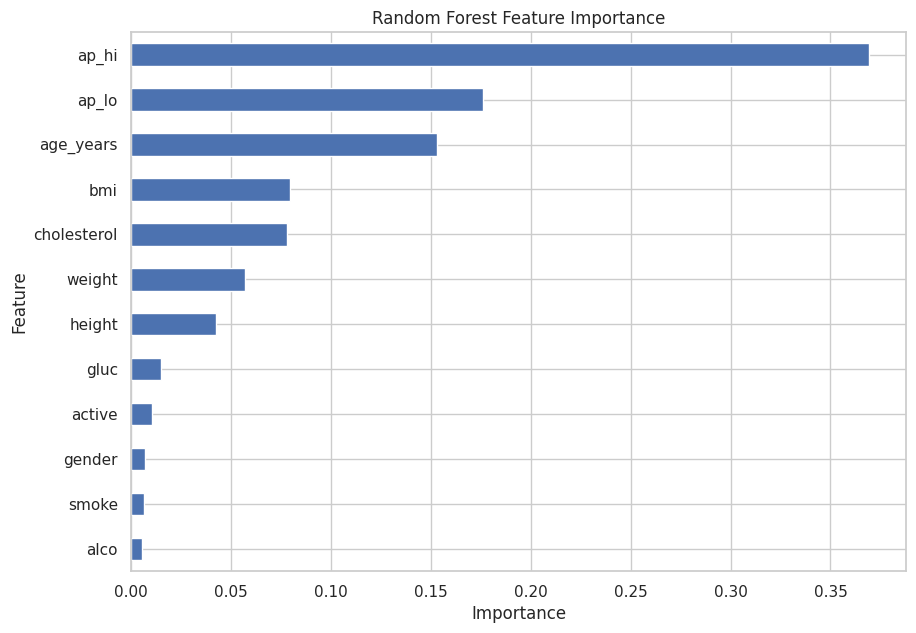

In [28]:
plt.figure(figsize=(10, 7))

feature_importance.sort_values().plot(
    kind='barh'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [29]:
##  SHAP Explainability
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [30]:
explainer = shap.TreeExplainer(random_forest_model)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


In [31]:
## Take 200 patients for SHAP
X_test_shap = X_test.sample(n=200, random_state=42)

# Create SHAP explainer
explainer_shap = shap.TreeExplainer(random_forest_model)

# Calculate SHAP values
shap_values = explainer_shap.shap_values(X_test_shap, check_additivity=False)

print("SHAP values calculated successfully!")
print("SHAP sample:", X_test_shap.shape)
print("SHAP values shape:", np.array(shap_values).shape)

SHAP values calculated successfully!
SHAP sample: (200, 12)
SHAP values shape: (200, 12, 2)


In [32]:
if isinstance(shap_values, list):

    shap_values_class1 = shap_values[1]

else:

    if len(shap_values.shape) == 3:
        shap_values_class1 = shap_values[:, :, 1]

    else:
        shap_values_class1 = shap_values

print("Class 1 SHAP shape:",
      shap_values_class1.shape)

Class 1 SHAP shape: (200, 12)


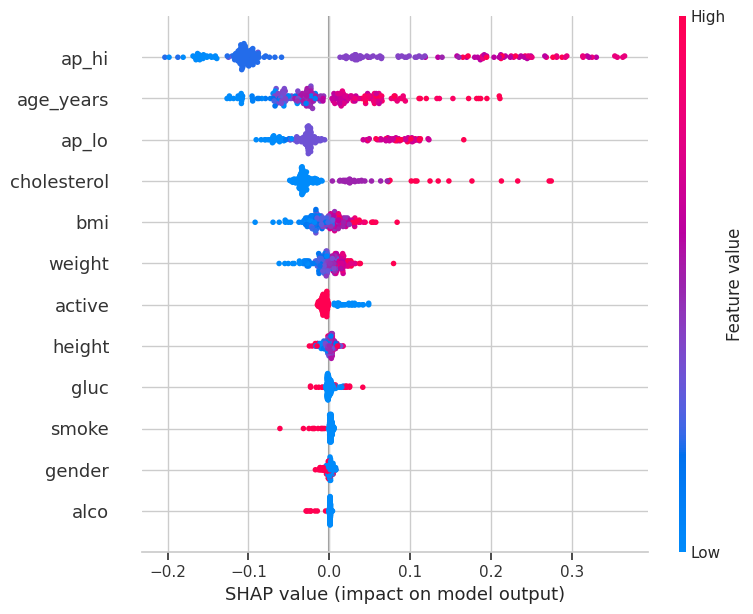

In [33]:
### Global SHAP Explanation
shap.summary_plot(
    shap_values_class1,
    X_test_shap
)

In [34]:
shap_importance = pd.Series(
    np.abs(shap_values_class1).mean(axis=0),
    index=X_test_shap.columns
).sort_values(ascending=False)

print("SHAP Feature Importance:")
print(shap_importance)

SHAP Feature Importance:
ap_hi          0.138712
age_years      0.054879
ap_lo          0.051029
cholesterol    0.039095
bmi            0.018225
weight         0.013146
active         0.009447
height         0.004711
gluc           0.003919
smoke          0.003069
gender         0.002855
alco           0.001827
dtype: float64


In [35]:
probs = random_forest_model.predict_proba(X_test_shap)[:, 1]

print("Highest-risk patient index:", probs.argmax(), "->", round(probs.max(), 3))
print("Lowest-risk patient index:", probs.argmin(), "->", round(probs.min(), 3))

Highest-risk patient index: 32 -> 0.885
Lowest-risk patient index: 100 -> 0.065


In [36]:
print(X_test_shap.iloc[[32, 100]].T)

                  42244       54546
gender         1.000000    1.000000
height       162.000000  154.000000
weight        60.000000   55.000000
ap_hi        160.000000  100.000000
ap_lo        100.000000   70.000000
cholesterol    1.000000    1.000000
gluc           1.000000    1.000000
smoke          0.000000    0.000000
alco           0.000000    0.000000
active         1.000000    1.000000
age_years     61.730322   40.585900
bmi           22.862369   23.191095


In [37]:
###  Patient-Level SHAP Explanation
patient_index = 32

patient = X_test_shap.iloc[patient_index]

patient_prediction = random_forest_model.predict(
    patient.to_frame().T
)[0]

patient_probability = random_forest_model.predict_proba(
    patient.to_frame().T
)[0][1]

print("Patient prediction:", patient_prediction)
print(
    "Predicted probability for class 1:",
    round(patient_probability, 4)
)

Patient prediction: 1
Predicted probability for class 1: 0.8851


In [38]:
patient_shap_values = shap_values_class1[patient_index]

base_value = explainer_shap.expected_value

if isinstance(base_value, np.ndarray):
    base_value = base_value[1]

patient_explanation = shap.Explanation(
    values=patient_shap_values,
    base_values=base_value,
    data=patient.values,
    feature_names=X_test_shap.columns
)

print("Patient SHAP explanation created successfully!")

Patient SHAP explanation created successfully!


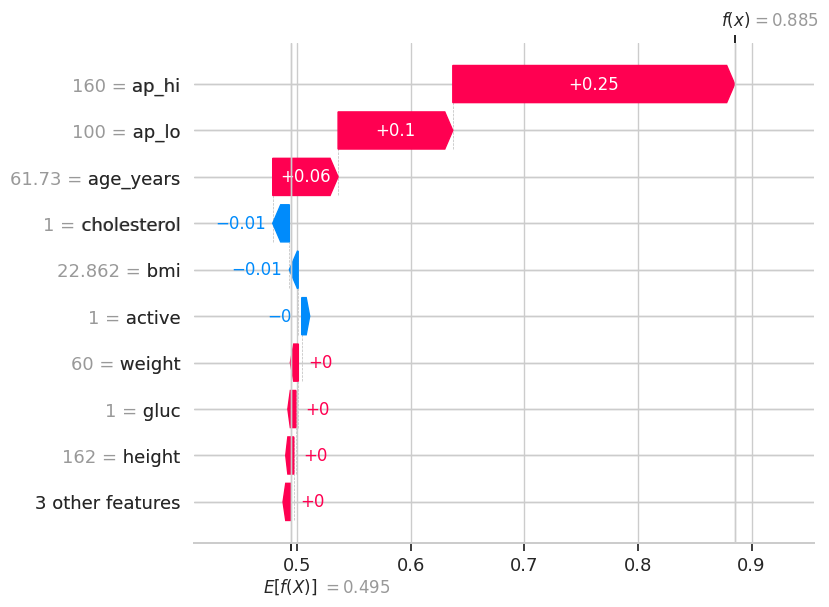

In [39]:
# Patient-level SHAP waterfall plot

shap.plots.waterfall(
    patient_explanation,
    max_display=10
)

In [40]:
print("========== FINAL PROJECT FINDINGS ==========")

print("\nModel Performance:")
print(f"Logistic Regression : {logistic_accuracy*100:.2f}%")
print(f"Decision Tree       : {decision_tree_accuracy*100:.2f}%")
print(f"Random Forest       : {random_forest_accuracy*100:.2f}%")
print(f"XGBoost             : {xgboost_accuracy*100:.2f}%")

print("\nBest Predictive Model:")
print(f"Random Forest with {random_forest_accuracy*100:.2f}% test accuracy")

print("\nExplainability Model:")
print("Random Forest")

print("\nExplainability Methods:")
print("1. Random Forest Feature Importance")
print("2. SHAP Global Explanation")
print("3. SHAP Patient-Level Explanation")

print("\nFinal Finding:")
print("The project successfully demonstrates an end-to-end")
print("machine learning workflow for cardiovascular disease")
print("prediction and explainability.")

print("\nNote:")
print("This project is a practical prototype and is not intended")
print("to replace clinical diagnosis or medical decision-making.")

========== FINAL PROJECT FINDINGS ==========

Model Performance:
Logistic Regression : 72.89%
Decision Tree       : 63.82%
Random Forest       : 73.68%
XGBoost             : 73.01%

Best Predictive Model:
Random Forest with 73.68% test accuracy

Explainability Model:
Random Forest

Explainability Methods:
1. Random Forest Feature Importance
2. SHAP Global Explanation
3. SHAP Patient-Level Explanation

Final Finding:
The project successfully demonstrates an end-to-end
machine learning workflow for cardiovascular disease
prediction and explainability.

Note:
This project is a practical prototype and is not intended
to replace clinical diagnosis or medical decision-making.


In [41]:
import joblib
joblib.dump(random_forest_model, 'random_forest_cardio.pkl')
print("Model saved successfully as random_forest_cardio.pkl")

Model saved successfully as random_forest_cardio.pkl
